**Professor:** Christian Mata Miquel

**Subject:** Data Analysis & Pattern Recognition

**Module:** Exploratory Data Analysis

**Student:** Max Rondeau Gómez

**Grup:** T21

# **FLIPPED CLASSROOM (STUDENT VERSION)**

A flipped classroom is an instructional approach in which students first encounter new content on their own (e.g., via videos, readings, or online materials) before class, and then use class time for active, guided practice, problem solving, and discussion with the instructor's support.

### **Instructions**

This is **pre-class work**. Before the in-class session:

1. Review the theory notebook `Clustering_analysis_PRML` (k-means, hierarchical/agglomerative clustering, Gaussian Mixture Models, and evaluation metrics: confusion matrix, adjusted Rand score, BIC).
2. Complete the **3 exercises** below on your own. They combine skills from previous sessions:
   - **S1** (Python basics: functions, loops)
   - **S2.1** (pandas data handling, missing values, seaborn visualization)
   - **S3** (k-means, hierarchical clustering, GMM, evaluation metrics)
3. Bring your completed notebook (even if incomplete or with errors) and upload your solution to ATENEA (also share your GitHub link).
4. Three students will be randomly selected to present their solutions for Exercise 1, Exercise 2, and
Exercise 3. The student will come to present his solution and it will be discussed with all your classmates.

**No solutions are included here on purpose** — the goal is to try, get stuck, and bring your questions to class.

### **Before to start**

### Quick self-check before you start (answer in your own words, no need to submit)

- What is the main difference between k-means and hierarchical clustering in terms of how the number of clusters is chosen?

-K-Means (S'ha de definir per endavant):

En aquest algorisme, el nombre de clústers ($K$) s'ha d'especificar obligatòriament abans de començar a executar el procés. Tu li has de dir a l'ordinador quants grups vols buscar exactament.Com que no tenim etiquetes prèvies ni una "veritat absoluta" (ground truth) per saber quin és el nombre correcte, s'utilitzen mètriques d'avaluació com la suma d'errors quadràtics (SSE) i s'analitza l'anomenat mètode del colze en una gràfica per intentar endevinar quina $K$ és la més òptima.



-Clustering Jeràrquic (Es decideix al final de manera visual):

En canvi, el clustering jeràrquic no exigeix fixar un nombre de clústers previ per fer funcionar l'algorisme.El que fa és calcular totes les relacions entre les dades i organitzar-les en un arbre anomenat dendrograma, on es veu clarament a quina distància s'uneixen els diferents elements o grups.Un cop dibuixat el dendrograma, pots escollir el nombre de clústers a posteriori, simplement decidint a quina altura o nivell de distància vols "tallar" l'arbre. Això et permet veure com quedaria la agrupació en diferents nivells de detall sense haver de recalcular-ho tot de zero.
- Why can k-means fail on non-spherical or unevenly-sized clusters?

El K-Means es un algoritmo de agrupamiento basado en centros (center-based clustering) que funciona calculando la distancia euclidiana (en línea recta) entre cada punto y los centroides, asignando cada elemento al centro más cercano para minimizar el error global (SSE). Debido a esta lógica rígida, tropieza en los siguientes casos:

Fallo con formas no globulares: Como el K-Means asume por definición que los clústeres son redondos y simétricos alrededor de un centroide, las fronteras que dibuja el algoritmo son siempre líneas o planos rectos. Si le das datos con formas curvas o de espiral, el algoritmo intentará cortarlos mediante líneas rectas, destrozando por completo la estructura real de los grupos.

Fallo con tamaños o densidades desiguales: Al depender estrictamente de la proximidad al centroide y de la varianza, el K-Means puede acabar partiendo de forma arbitraria un clúster grande y real en varios trozos, o bien hacer que un centroide se desplace y absorba erróneamente puntos de un grupo vecino más pequeño o menos denso.
- What does the BIC criterion help us choose in a Gaussian Mixture Model?

el BIC calcula una puntuación para cada cantidad de clústers probada, ayudándote a escoger matemáticamente cuántos grupos necesitas realmente sin complicar las cosas de más.

El criterio BIC (Bayesian Information Criterion) nos ayuda a escoger el número óptimo de clústers (o componentes) que debe tener un Modelo de Mezcla Gaussiana (Gaussian Mixture Model, GMM).

If you can't answer these after reviewing the theory notebook, note it down — we'll start class with these questions.


---

## **Exercise 1:** K-means on the Penguins dataset (S2 + S3)

We'll reuse the `penguins` dataset from the S2 session (Palmer Archipelago penguins), and now apply clustering to it.

```python
import seaborn as sns
penguins = sns.load_dataset('penguins')
```

a) **(S2.1 recap)** Keep only the numeric columns (`bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g`). Before dropping anything, **check how many missing values** each column has (`.isna().sum()`). Then drop rows with missing values (`.dropna()`) and **confirm the resulting dataframe is clean** (no `NaN` left).

In [17]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix
from sklearn.metrics.cluster import adjusted_rand_score
from sklearn.preprocessing import LabelEncoder, StandardScaler

# 1. Carreguem el dataset original dels pingüins
penguins = sns.load_dataset('penguins')

# Mostrem les primeres 10 files
display(penguins.head(10))

# 2. Definim les columnes numèriques que ens interessen
num_cols = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']

# 3. Comprovem quants valors nuls té cada columna exactament
print("\n--- COMPROVACIÓ DE VALORS NULS (NaN) ---")
print(penguins[num_cols].isna().sum())

# Filtrem i mostrem només les files que tenen almenys un valor nul en les columnes numèriques
files_amb_nuls = penguins[penguins[num_cols].isna().any(axis=1)]

print(f"Nombre total de files amb algun NaN: {len(files_amb_nuls)}")
display(files_amb_nuls)

#com ara sabem que quan tenim NaN (en valors numerics), tota la fila no tenim dades, el que farem sera eliminar aquestes files:
penguins_clean = penguins[num_cols].dropna().copy()
display(penguins_clean.head(10))
print("--- MOSTRA DEL DATASET NETEJAT (sense NaN) ---")
print(penguins_clean[num_cols].isna().sum())

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,Male
6,Adelie,Torgersen,38.9,17.8,181.0,3625.0,Female
7,Adelie,Torgersen,39.2,19.6,195.0,4675.0,Male
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN



--- COMPROVACIÓ DE VALORS NULS (NaN) ---
bill_length_mm       2
bill_depth_mm        2
flipper_length_mm    2
body_mass_g          2
dtype: int64
Nombre total de files amb algun NaN: 2


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,39.1,18.7,181.0,3750.0
1,39.5,17.4,186.0,3800.0
2,40.3,18.0,195.0,3250.0
4,36.7,19.3,193.0,3450.0
5,39.3,20.6,190.0,3650.0
6,38.9,17.8,181.0,3625.0
7,39.2,19.6,195.0,4675.0
8,34.1,18.1,193.0,3475.0
9,42.0,20.2,190.0,4250.0
10,37.8,17.1,186.0,3300.0


--- MOSTRA DEL DATASET NETEJAT (sense NaN) ---
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
dtype: int64


b) **(normalization)** The four numeric columns live on very different scales (millimeters vs. grams). **Normalize them** with `StandardScaler` (mean 0, standard deviation 1) before clustering, since k-means uses Euclidean distance and would otherwise let `body_mass_g` dominate the result just because its raw values are much larger.

In [19]:
# b) YOUR CODE HERE: normalize the numeric columns with StandardScaler
# 1. Creem l'objecte StandardScaler
scaler = StandardScaler()

# 2. Ajustem i transformem les columnes numèriques del nostre dataset net
penguins_scaled = scaler.fit_transform(penguins_clean[num_cols])

# 3. Opcionalment, creem un DataFrame nou amb les dades escalades per veure-ho en format taula
penguins_scaled_df = pd.DataFrame(penguins_scaled, columns=num_cols)

print("--- MOSTRA DE LES DADES NORMALITZADES (mitjana 0, desviació 1) ---")
display(penguins_scaled_df.head(2))

--- MOSTRA DE LES DADES NORMALITZADES (mitjana 0, desviació 1) ---


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,-0.884499,0.785449,-1.418347,-0.564142
1,-0.811126,0.126188,-1.062250,-0.501703


c) Apply **k-means** with `n_clusters=3` (there are 3 penguin species) to the **normalized** columns. Store the resulting labels in a variable `kmeans_labels`.

In [21]:
# c) YOUR CODE HERE: apply KMeans with n_clusters=3 on the normalized data
# 1. Creem el model de KMeans amb 3 clústers (i un random_state per tenir resultats reproductibles)
     ## Justificació dels paràmetres del model K-Means: n_clusters=3 (enunciat); random_state=42: Fixa la llavor
#       aleatòria per garantir la reproductibilitat dels resultats, assegura que cada vegada que executem el codi
#       s'obtinguin exactament les mateixes assignacions de clústers; n_init=10: Executa l'algorisme 10 vegades
#       amb diferents centroides inicials aleatoris per evitar quedar-nos atrapats en òptims locals i seleccionar
#       automàticament la millor partició (mínim SSE).
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

# 2. Ajustem el model utilitzant les dades normalitzades
kmeans.fit(penguins_scaled)

# 3. Guardem les etiquetes dels clústers assignades a cada pingüí
kmeans_labels = kmeans.labels_

print("Primeres 10 etiquetes de clúster assignades:", kmeans_labels[:10])

Primeres 10 etiquetes de clúster assignades: [2 2 2 2 2 2 2 2 0 2]


d) Add the cluster labels as a new column in your (unscaled) dataframe, and make a **scatterplot** (`bill_length_mm` vs `flipper_length_mm`) colored by `kmeans_labels`, as done in the S3 notebook and in S2.1. Also make two **pairplots** of the four numeric variables: one colored by the real `species`, and one colored by `kmeans_labels`, to visually compare them side by side (as done with `hue` in S2.1).



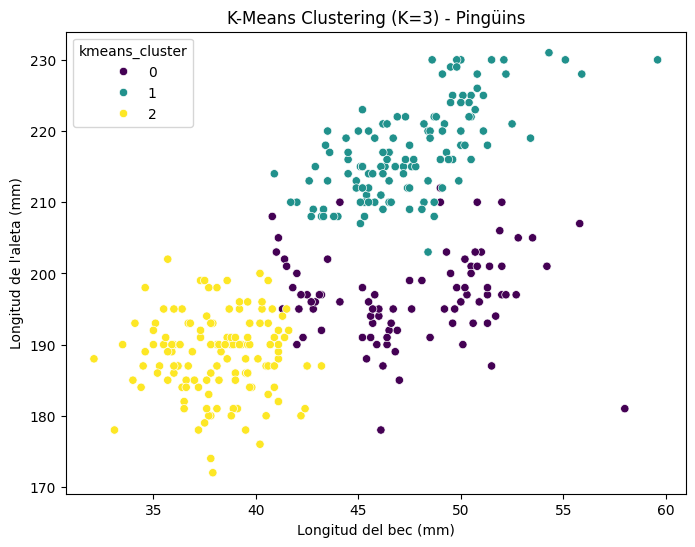

Pairplot basat en les espècies reals:


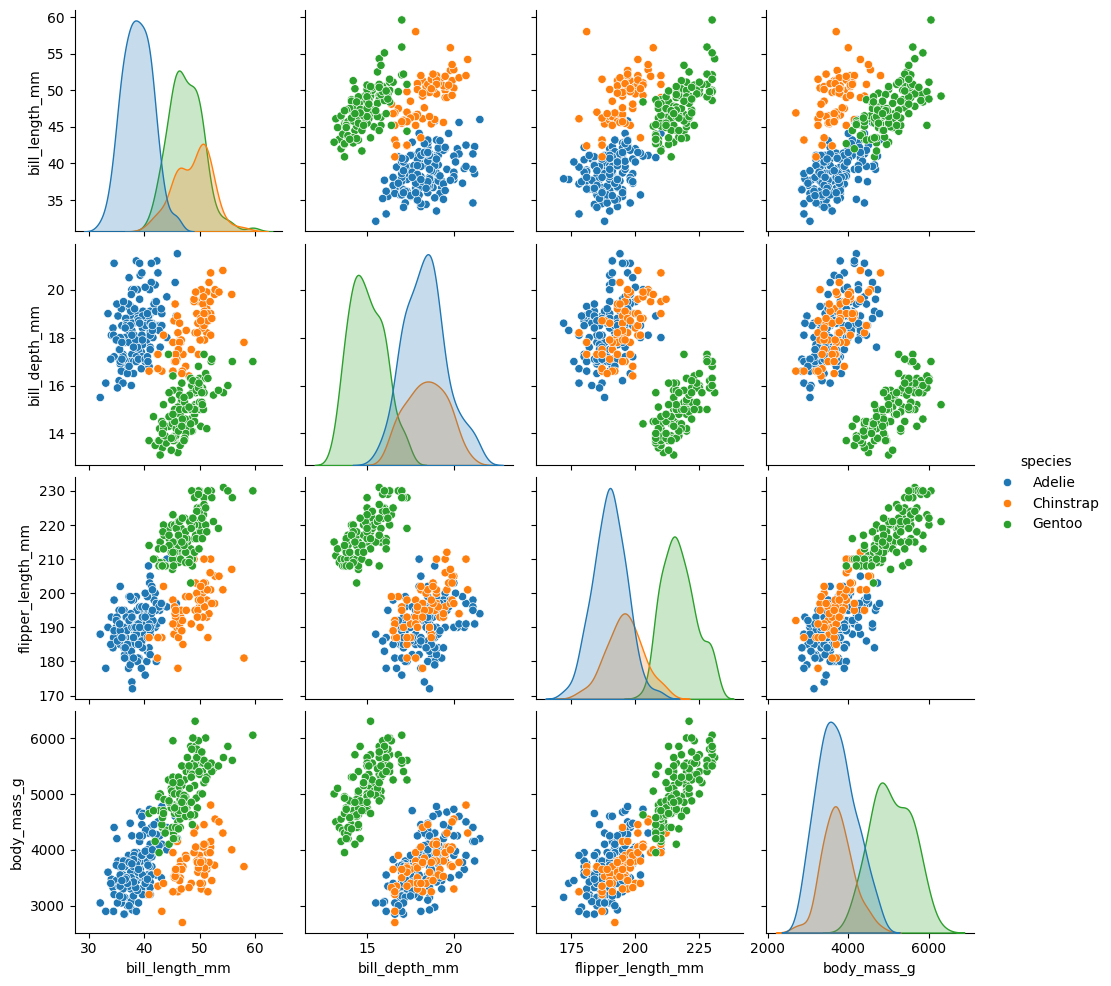

Pairplot basat en els clústers trobats per K-Means:


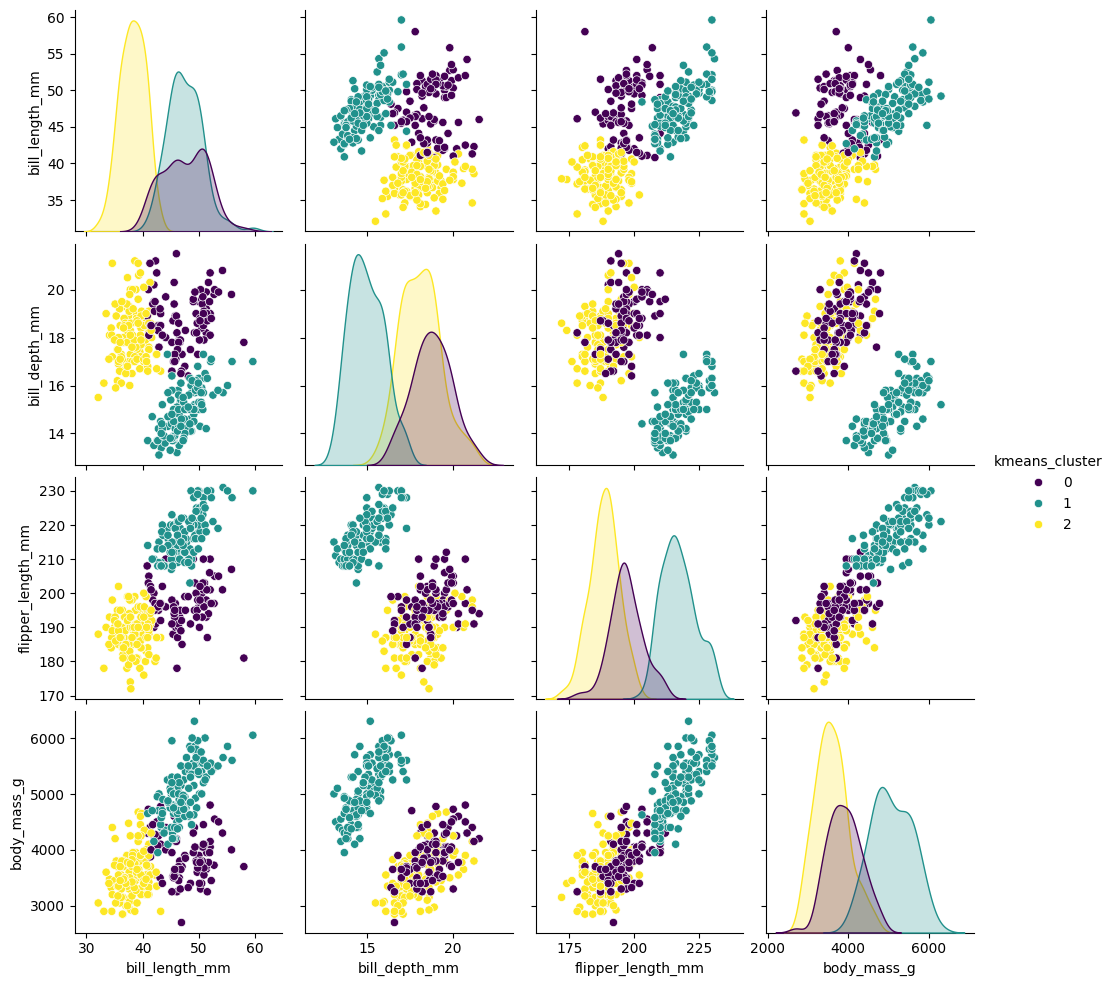

In [24]:
# d) YOUR CODE HERE: add kmeans_labels to penguins_clean, plot bill_length_mm vs flipper_length_mm colored by cluster,
#    and make two pairplots (one hue='species', one hue=kmeans cluster)
penguins_clean = penguins[num_cols + ['species']].dropna().copy()
# 1. Afegim les etiquetes del k-means com una columna nova al nostre dataframe no escalat (penguins_clean)
penguins_clean['kmeans_cluster'] = kmeans_labels

# 2. Fem el scatterplot: bill_length_mm vs flipper_length_mm acolorit pel clúster predit
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=penguins_clean,
    x='bill_length_mm',
    y='flipper_length_mm',
    hue='kmeans_cluster',
    palette='viridis',
)
plt.title('K-Means Clustering (K=3) - Pingüins')
plt.xlabel('Longitud del bec (mm)')
plt.ylabel('Longitud de l\'aleta (mm)')
plt.show()

# 3. Primer pairplot: acolorit per les ESPÈCIES REALS
print("Pairplot basat en les espècies reals:")
sns.pairplot(penguins_clean, hue='species', vars=num_cols)
plt.show()

# 4. Segon pairplot: acolorit pels CLÚSTERS DE K-MEANS
print("Pairplot basat en els clústers trobats per K-Means:")
sns.pairplot(penguins_clean, hue='kmeans_cluster', vars=num_cols, palette='viridis')
plt.show()

e) Now compare the clusters found by k-means with the **real species** (`species` column). Compute a **confusion matrix** (`sklearn.metrics.confusion_matrix`) between `kmeans_labels` and the real species, and the **adjusted Rand score** (`adjusted_rand_score`).


--- MATRIU DE CONFUSIÓ (sklearn) ---
[[ 24   0 127]
 [ 63   0   5]
 [  0 123   0]]


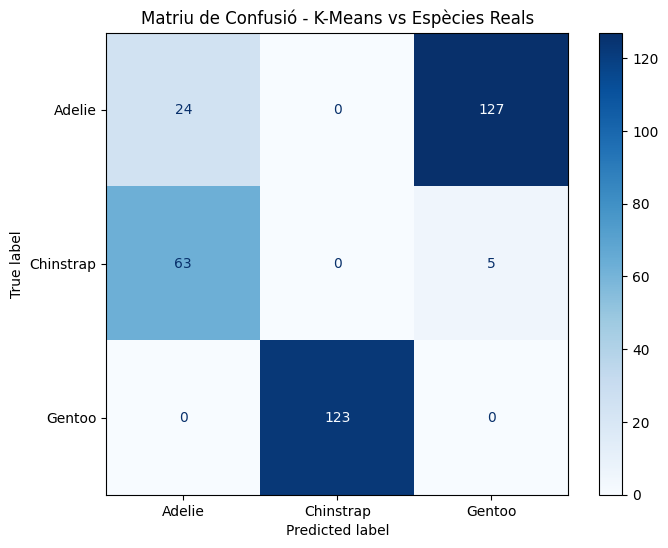


--- ADJUSTED RAND SCORE (ARI) ---
Puntuació ARI: 0.7928


In [41]:
# e) YOUR CODE HERE: confusion matrix and adjusted Rand score vs real 'species'
from sklearn.metrics import ConfusionMatrixDisplay


# 1. Transformem les espècies de text (string) a números enters (0, 1, 2)
le = LabelEncoder()
y_true_numeric = le.fit_transform(penguins_clean['species'])

# 2. Calculem la matriu de confusió de manera nativa amb sklearn
cm = confusion_matrix(y_true_numeric, kmeans_labels)

print("--- MATRIU DE CONFUSIÓ (sklearn) ---")
print(cm)

# 3. Dibuixem la matriu amb l'estil visual de Scikit-Learn (usant les espècies originals com a etiquetes)
fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
disp.plot(cmap=plt.cm.Blues, ax=ax)
plt.title('Matriu de Confusió - K-Means vs Espècies Reals')
plt.show()

# 4. Calculem l'Adjusted Rand Score (l'ARI funciona igual amb text o números)
ari = adjusted_rand_score(penguins_clean['species'], kmeans_labels)
print(f"\n--- ADJUSTED RAND SCORE (ARI) ---")
print(f"Puntuació ARI: {ari:.4f}")

f) In a short comment or markdown cell: does k-means recover the 3 species well? Which species seem to get confused with each other, if any? Did normalizing the features change the result compared to using the raw values?

  The K-means algorithm identifies the species quite well, as the ARI score of 0.79 indicates a high level of agreement. However, there is still room for improvement in the clustering accuracy.

  For example, the Gentoo species is very clearly defined, but there is considerable confusion between Adelie and Chinstrap.

  Normalization has definitely changed the results, because otherwise, the body_mass_g variable would dominate the other variables due to its larger values.

---

## **Exercise 2:** Hierarchical clustering + a custom distance function (S1 + S3)

We'll use the small synthetic dataset from the S3 notebook:

```python
import numpy as np
X = np.array([[1, 2], [1, 4], [1, 0], [5, 6], [5, 3], [5, 0]])
```

a) **(control de datos)** Even on a small synthetic array like this one, it's good practice to check for missing values before doing anything else: use `np.isnan(X).any()` to confirm there are none.

b) **(normalization)** Normalize `X` with `StandardScaler` before clustering (even though both coordinates here happen to be on a similar scale, this should always be the default first step for any distance-based method, so that you don't forget it on a real dataset where scales usually differ a lot).

c) **(S1 recap)** Write a plain Python function `euclidean_distance(p1, p2)` **without using numpy or sklearn**, using only a `for` loop over the coordinates, that computes the Euclidean distance between two points (given as lists or tuples). Test it on `euclidean_distance(X[0], X[3])` and check it against `np.linalg.norm(X[0]-X[3])`.

d) Apply **Agglomerative Clustering** with `n_clusters=2` to the **normalized** `X` (as done in the S3 notebook), and plot the **dendrogram** using `scipy.cluster.hierarchy.dendrogram` and `linkage`.

e) Also apply **k-means** with `n_clusters=2` to the same normalized data.

f) Compare the cluster labels obtained by agglomerative clustering and k-means — are they identical for this small dataset? (Print both label arrays, and make a side-by-side scatterplot of the original points colored by each method's labels.)

g) **(S1 recap)** Write a function `cluster_sizes(labels)` that takes an array of cluster labels and returns a **dictionary** with the count of observations per cluster (reuse the dictionary-counting pattern from S1), and apply it to both clusterings.

In [2]:
import numpy as np
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt

X = np.array([[1, 2], [1, 4], [1, 0], [5, 6], [5, 3], [5, 0]])

# a) YOUR CODE HERE: check for missing values with np.isnan(X).any()
te_nuls = np.isnan(X).any()
print("El dataset conté NaN?", te_nuls)

El dataset conté NaN? False


In [3]:
# b) YOUR CODE HERE: normalize X with StandardScaler
# 1. Creem l'objecte StandardScaler
scaler = StandardScaler()

# 2. Ajustem i transformem les dades de X
X_scaled = scaler.fit_transform(X)

print("--- DADES NORMALITZADES (X_scaled) ---")
print(X_scaled)

--- DADES NORMALITZADES (X_scaled) ---
[[-1.         -0.23354968]
 [-1.          0.70064905]
 [-1.         -1.16774842]
 [ 1.          1.63484778]
 [ 1.          0.23354968]
 [ 1.         -1.16774842]]


In [4]:
# c) YOUR CODE HERE: plain-Python euclidean_distance function using a for loop (no numpy/sklearn)
def euclidean_distance(p1, p2):
    suma_quadrats = 0
    # Recorrem les coordenades amb un bucle for
    for i in range(len(p1)):
        diferencia = p1[i] - p2[i]
        suma_quadrats = suma_quadrats + (diferencia ** 2)

    # Retornem l'arrel quadrada de la suma dels quadrats
    return suma_quadrats ** 0.5

# Testejem la nostra funció amb X[0] i X[3]
distancia_manual = euclidean_distance(X[0], X[3])
print("Distància calculada a mà:", distancia_manual)

# Ho comprovem amb la norma de numpy per veure que dóna exactament el mateix
distancia_numpy = np.linalg.norm(X[0] - X[3])
print("Distància amb numpy.linalg.norm:", distancia_numpy)

Distància calculada a mà: 5.656854249492381
Distància amb numpy.linalg.norm: 5.656854249492381


Etiquetes del Clustering Jeràrquic: [1 1 1 0 0 0]


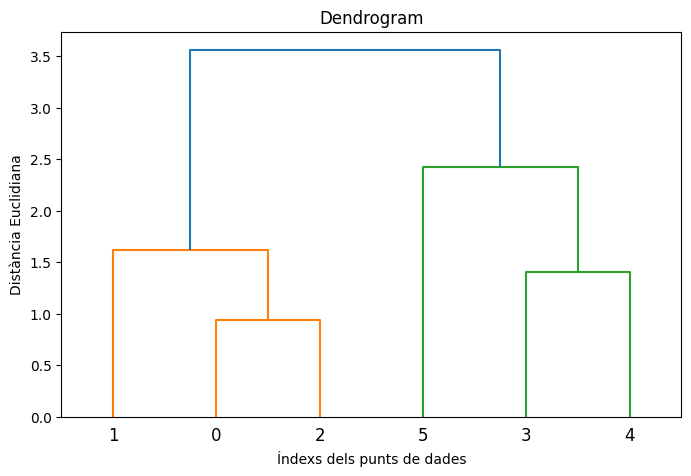

In [5]:
# d) YOUR CODE HERE: agglomerative clustering on X_scaled + dendrogram
# 1. Apliquem Agglomerative Clustering amb n_clusters=2 sobre les dades normalitzades (X_scaled)
agg_cluster = AgglomerativeClustering(n_clusters=2)
agg_labels = agg_cluster.fit_predict(X_scaled)

print("Etiquetes del Clustering Jeràrquic:", agg_labels)

# 2. Calculem la matriu 'linkage' per poder dibuixar el dendrograma (fem servir el mètode 'ward' per defecte)
linked = linkage(X_scaled, method='ward')

# 3. Dibuixem el dendrograma
plt.figure(figsize=(8, 5))
dendrogram(linked)
plt.title('Dendrogram')
plt.xlabel('Índexs dels punts de dades')
plt.ylabel('Distància Euclidiana')
plt.show()

In [6]:
# e) YOUR CODE HERE: k-means clustering with n_clusters=2 on X_scaled
# 1. Apliquem K-Means amb n_clusters=2 sobre les dades normalitzades (X_scaled)
# (Posem un random_state fix perquè ens doni sempre el mateix resultat en cada execució)
kmeans_model = KMeans(n_clusters=2, random_state=42)
kmeans_labels_ex2 = kmeans_model.fit_predict(X_scaled)

print("Etiquetes obtingudes per K-Means:", kmeans_labels_ex2)

Etiquetes obtingudes per K-Means: [0 0 0 1 1 1]


Etiquetes Agglomerative Clustering: [1 1 1 0 0 0]
Etiquetes K-Means: [0 0 0 1 1 1]


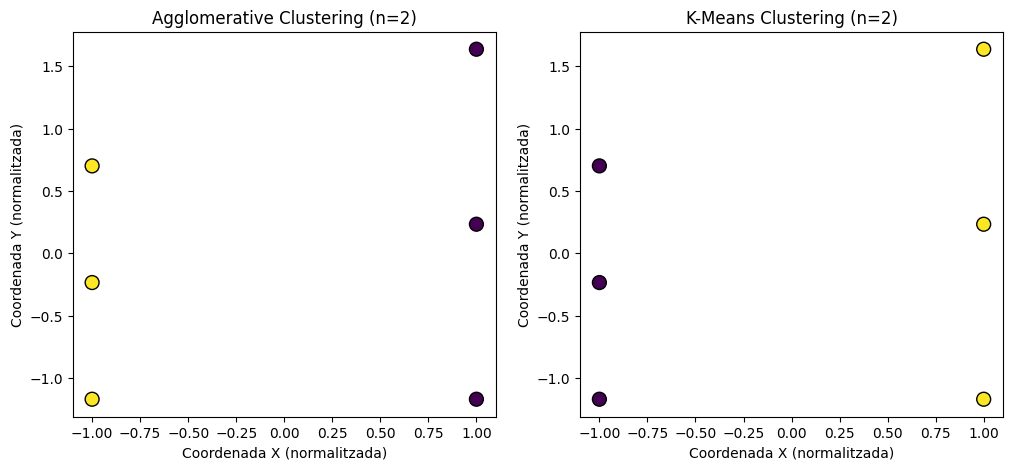

In [8]:
# f) YOUR CODE HERE: compare both label arrays and make a side-by-side scatterplot

# 1. Imprimim i comparem directament els dos arrays d'etiquetes
print("Etiquetes Agglomerative Clustering:", agg_labels)
print("Etiquetes K-Means:", kmeans_labels_ex2)

# 2. Fem un gràfic doble (side-by-side scatterplot) per comparar visualment
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Gràfic 1: Clustering Jeràrquic (Agglomerative)
scatter1 = ax1.scatter(X_scaled[:, 0], X_scaled[:, 1], c=agg_labels, cmap='viridis', s=100, edgecolor='k')
ax1.set_title('Agglomerative Clustering (n=2)')
ax1.set_xlabel('Coordenada X (normalitzada)')
ax1.set_ylabel('Coordenada Y (normalitzada)')

# Gràfic 2: K-Means
scatter2 = ax2.scatter(X_scaled[:, 0], X_scaled[:, 1], c=kmeans_labels_ex2, cmap='viridis', s=100, edgecolor='k')
ax2.set_title('K-Means Clustering (n=2)')
ax2.set_xlabel('Coordenada X (normalitzada)')
ax2.set_ylabel('Coordenada Y (normalitzada)')

plt.show()


We observe that, for this very small dataset, both models assign the same groups, with only one difference: the group labels are swapped (where one model assigns label 1, the other assigns label 0). This is the only difference between them.

In [9]:
# g) YOUR CODE HERE: cluster_sizes function using a dictionary
def cluster_sizes(labels):
    # Paso 1: Creamos un diccionari buit on guardarem els recomptes
    counts = {}

    # Paso 2: Recorrem un a un tots els elements de l'array d'etiquetes amb un bucle for
    for label in labels:
        # Paso 3: Comprovem si aquesta etiqueta ja l'haviem vista abans al diccionari
        if label in counts:
            # Si ja existeix, sumem 1 al seu comptador actual
            counts[label] += 1
        else:
            # Si és la primera vegada que la veiem, la inicialitzem a 1
            counts[label] = 1

    # Paso 4: Retornem el diccionari ple amb els resultats finals
    return counts

# Aplicamos la función al Clustering Jerárquico
print("Mides dels clústers (Agglomerative):", cluster_sizes(agg_labels))

# Aplicamos la función al K-Means
print("Mides dels clústers (K-Means):", cluster_sizes(kmeans_labels_ex2))

Mides dels clústers (Agglomerative): {np.int64(1): 3, np.int64(0): 3}
Mides dels clústers (K-Means): {np.int32(0): 3, np.int32(1): 3}


---

## **Exercise 3:** Choosing the number of clusters with GMM + BIC (S1+S2+S3)

We'll reuse the `diamonds` sample from the S2.1 session:

```python
diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)
```

a) **(S2 recap)** Select only the numeric columns `carat`, `depth`, `table`, `price` into a new dataframe `diamonds_num`. **Check for missing values** (`.isna().sum()`) and drop any rows with `NaN` if needed, confirming the data is clean afterwards.

b) **(exploración, opcional pero recomendado)** Plot the distribution of `price` (histogram) and mark the mean and mean ± one standard deviation with vertical lines, as done in S2.1 — this helps you see just how skewed and large-scale `price` is compared to the other three variables.

c) **(normalization)** `carat`, `depth`, `table` and `price` are on very different scales (price ranges into the thousands of dollars, while depth/table are percentages around 50–70). **Normalize all four columns with `StandardScaler`** before fitting the GMM — otherwise `price` alone will dominate the covariance structure the model is trying to fit.

d) As done in the S3 notebook, fit a **Gaussian Mixture Model** on the **normalized** data for a range of number of components from 1 to 8, store the **BIC** value for each in a list, and plot BIC vs number of components.

e) Find the number of components that **minimizes** the BIC, and fit the final GMM model with that number of components. Store the predicted cluster labels in `gmm_labels`.

f) Add `gmm_labels` as a new column to your (unscaled, more interpretable) `diamonds_num` and create a **pairplot** (`sns.pairplot`) of `carat`, `depth`, `table`, `price`, colored by `gmm_labels` (`hue`), as done in S2.1. Also make a **jointplot** (`sns.jointplot`) of `carat` vs `price` to zoom into the relationship driving most of the clustering.

g) In a short comment or markdown cell: does the optimal number of clusters found by BIC seem reasonable when you look at the pairplot? Would you have guessed the same number just by eye? Did normalizing the data change the optimal number of components compared to fitting the GMM on the raw values?

In [29]:
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import mixture
from sklearn.preprocessing import StandardScaler

diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)

# a) YOUR CODE HERE: select numeric columns into diamonds_num, check missing values, dropna() and confirm it's clean
display(diamonds.head(10))

cols_interes = ['carat', 'depth', 'table', 'price']
diamonds_num = diamonds[cols_interes].copy()

# 3. Comprovem si hi ha valors perduts (nuls) columna per columna
print("--- COMPROVACIÓ DE VALORS NULS (Abans de netejar) ---")
print(diamonds_num.isna().sum())



,carat,cut,color,clarity,depth,table,price,x,y,z
1388,0.24,Ideal,G,VVS1,62.1,56.0,559,3.97,4.00,2.47
50052,0.58,Very Good,F,VVS2,60.0,57.0,2201,5.44,5.42,3.26
41645,0.40,Ideal,E,VVS2,62.1,55.0,1238,4.76,4.74,2.95
42377,0.43,Premium,E,VVS2,60.8,57.0,1304,4.92,4.89,2.98
17244,1.55,Ideal,E,SI2,62.3,55.0,6901,7.44,7.37,4.61
1608,1.00,Fair,E,SI2,55.4,62.0,3011,6.63,6.59,3.66
46398,0.51,Ideal,F,VS1,60.2,56.0,1765,5.22,5.24,3.15
45493,0.52,Ideal,D,VS2,62.0,56.0,1679,5.17,5.19,3.21
49385,0.62,Premium,E,VS2,60.0,59.0,2102,5.58,5.56,3.34
10460,1.14,Ideal,H,SI1,60.3,57.0,4789,6.79,6.85,4.11


--- COMPROVACIÓ DE VALORS NULS (Abans de netejar) ---
carat    0
depth    0
table    0
price    0
dtype: int64


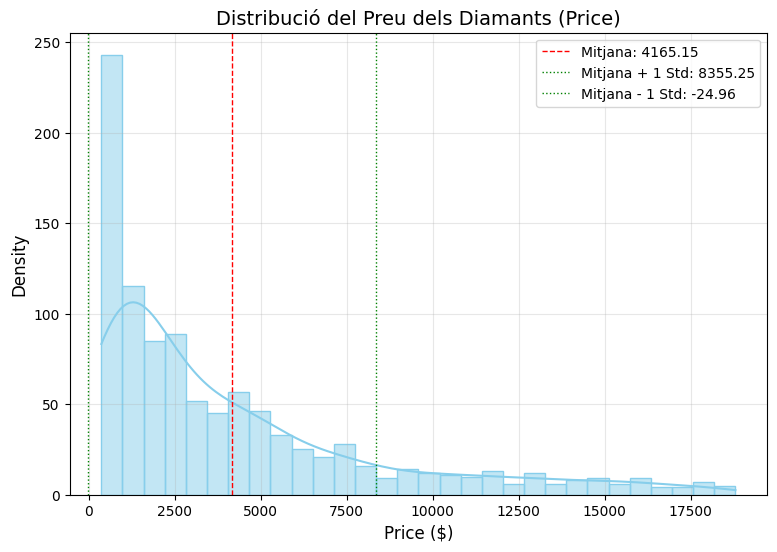

In [19]:
# b) YOUR CODE HERE: histogram of 'price' with mean and mean +/- std lines

# 1. Calculem la mitjana i la desviació estàndard de la columna 'price'
preu_mitjana = diamonds_num['price'].mean()
preu_std = diamonds_num['price'].std()

# 2. Dibuixem l'histograma amb Seaborn / Matplotlib
plt.figure(figsize=(9, 6))
sns.histplot(diamonds_num['price'], bins=30, kde=True, color='skyblue', edgecolor='skyblue')

# 3. Afegim les línies verticals per la mitjana i la desviació estàndard
plt.axvline(preu_mitjana, color='red', linestyle='--', linewidth=1, label=f'Mitjana: {preu_mitjana:.2f}')
plt.axvline(preu_mitjana + preu_std, color='green', linestyle=':', linewidth=1, label=f'Mitjana + 1 Std: {preu_mitjana + preu_std:.2f}')
plt.axvline(preu_mitjana - preu_std, color='green', linestyle=':', linewidth=1, label=f'Mitjana - 1 Std: {preu_mitjana - preu_std:.2f}')

# 4. Personalitzem el gràfic
plt.title('Distribució del Preu dels Diamants (Price)', fontsize=14)
plt.xlabel('Price ($)', fontsize=12)
plt.ylabel('Density', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [23]:
# c) YOUR CODE HERE: normalize the 4 numeric columns with StandardScaler
# 1. Creem l'objecte StandardScaler
scaler_gmm = StandardScaler()

# 2. Ajustem i transformem les dades numèriques dels diamants
diamonds_scaled = scaler_gmm.fit_transform(diamonds_num)

print("--- DADES NORMALITZADES (Primeres 5 files) ---")
print(diamonds_scaled[:5])


--- DADES NORMALITZADES (Primeres 5 files) ---
[[-1.19910658  0.24293476 -0.5945033  -0.86106479]
 [-0.50515554 -1.25622185 -0.16017886 -0.46899303]
 [-0.87254138  0.24293476 -1.02882775 -0.69893524]
 [-0.81131041 -0.68511457 -0.16017886 -0.68317596]
 [ 1.47464596  0.38571158 -1.02882775  0.65325864]]


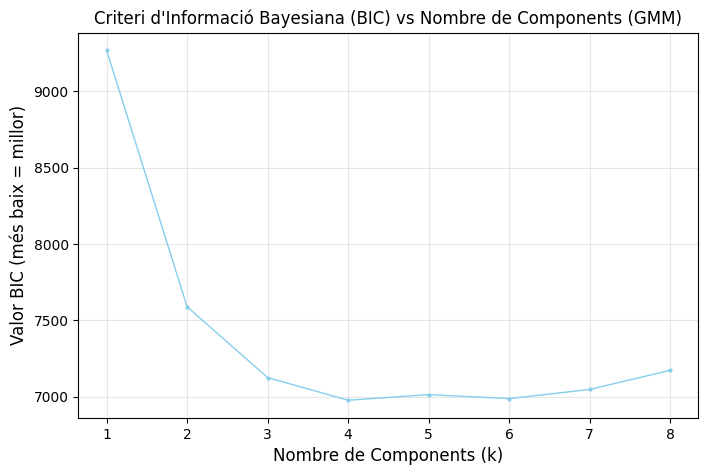

In [26]:
# d) YOUR CODE HERE: fit GMM for n_components = 1..8 on diamonds_scaled, store BIC values, plot BIC vs n_components
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture
# 1. Definim el rang de components que volem provar (de l'1 al 8)
rang_components = range(1, 9)
llista_bic = []

# 2. Bucle per ajustar un GMM per a cada nombre de components i calcular el seu BIC
for k in rang_components:
    # Creem el model GMM (fem servir random_state per tenir resultats estables)
    gmm = GaussianMixture(n_components=k, random_state=42)

    # Ajustem el model a les dades normalitzades
    gmm.fit(diamonds_scaled)

    # Calculem i guardem el BIC del model actual
    bic_val = gmm.bic(diamonds_scaled)
    llista_bic.append(bic_val)

# 3. Dibuixem la corba de BIC en funció del nombre de components
plt.figure(figsize=(8, 5))
plt.plot(rang_components, llista_bic, marker='o', linestyle='-', color='skyblue', linewidth=1, markersize=2)
plt.title('Criteri d\'Informació Bayesiana (BIC) vs Nombre de Components (GMM)')
plt.xlabel('Nombre de Components (k)', fontsize=12)
plt.ylabel('Valor BIC (més baix = millor)', fontsize=12)
plt.xticks(rang_components)
plt.grid(True, alpha=0.3)
plt.show()

In [32]:
# e) YOUR CODE HERE: find the number of components that minimizes BIC and fit the final GMM

# 1. en lapartat anterior i amb ajuda de la grafica em vist que el nombre òptim de components trobat amb el BIC es (k = 4)
best_n = 4

# 2. Creem i ajustem el model GMM definitiu amb aquest nombre de components
gmm_final = GaussianMixture(n_components=best_n, random_state=42)
gmm_final.fit(diamonds_scaled)

# 3. Prediem i guardem les etiquetes dels clústers a gmm_labels
gmm_labels = gmm_final.predict(diamonds_scaled)

print("Etiquetes de clúster GMM generades (primeres 20):", gmm_labels[:20])

Etiquetes de clúster GMM generades (primeres 20): [0 3 0 0 1 2 3 3 2 2 0 1 2 3 2 1 2 3 1 0]


,carat,depth,table,price,cluster
1388,0.24,62.1,56.0,559,0
50052,0.58,60.0,57.0,2201,3
41645,0.40,62.1,55.0,1238,0
42377,0.43,60.8,57.0,1304,0
17244,1.55,62.3,55.0,6901,1


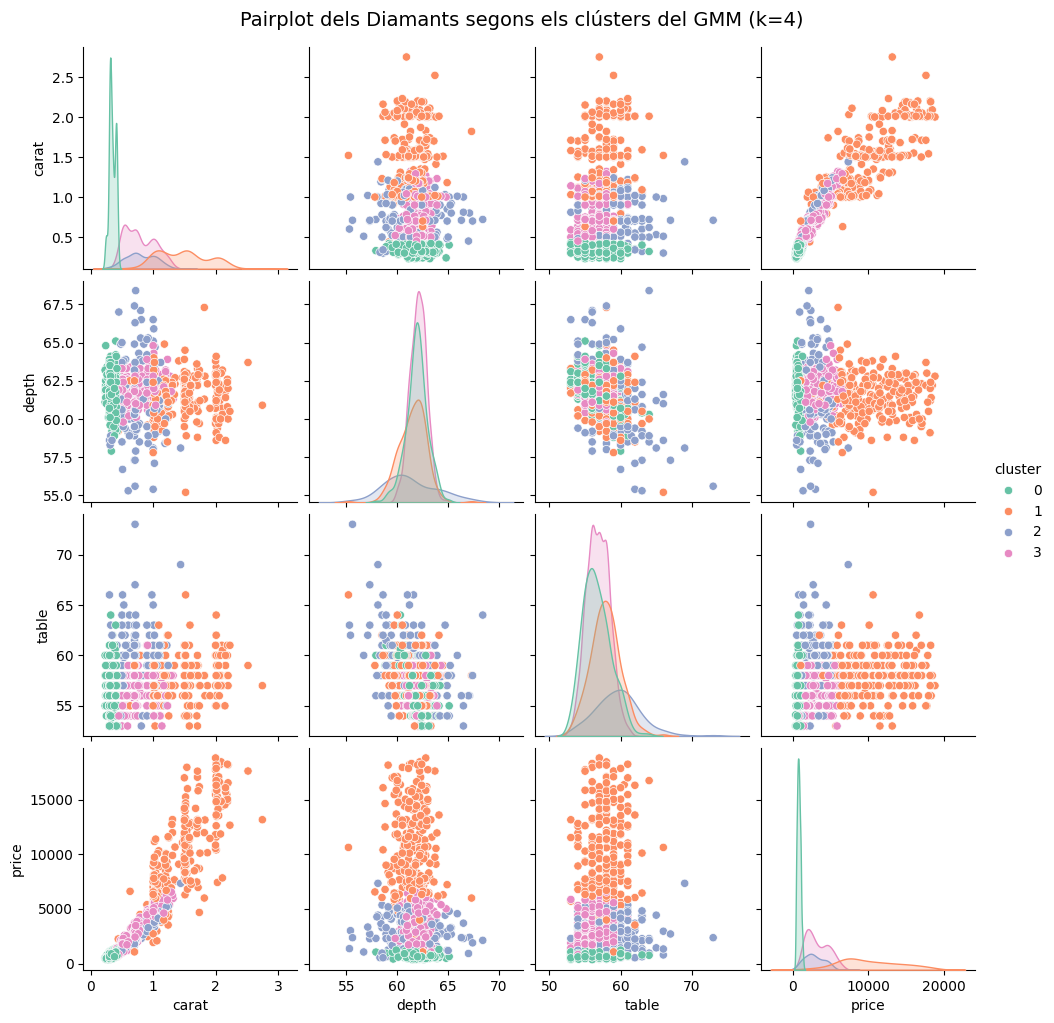

<Figure size 800x600 with 0 Axes>

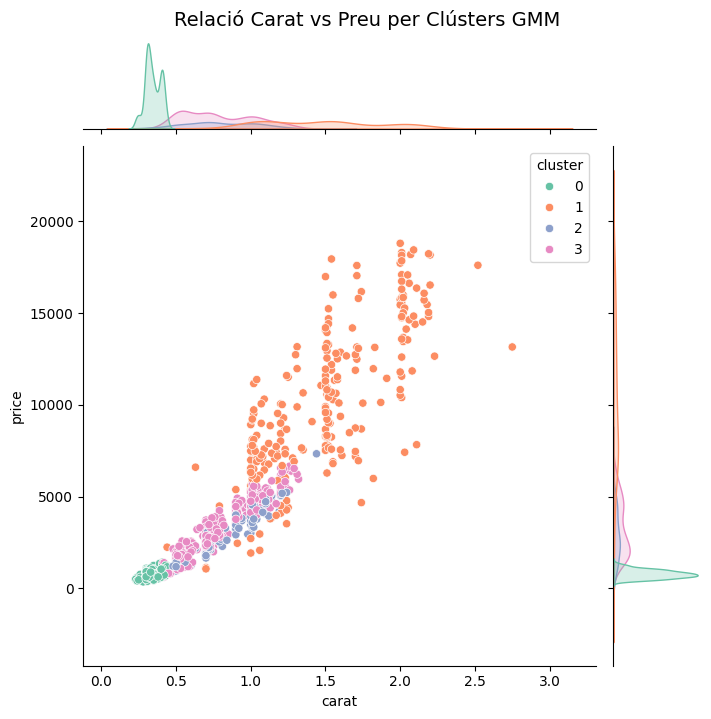

In [33]:
# f) YOUR CODE HERE: add gmm_labels to diamonds_num (unscaled) and make a pairplot + a jointplot (carat vs price)
# 1. Afegim les etiquetes del GMM com una columna nova al dataframe original no escalat
diamonds_num['cluster'] = gmm_labels

display(diamonds_num.head(5))

# 2. Creem el pairplot de totes les variables numèriques pintades pel clúster (hue)
# Fem servir palette='viridis' o 'Set2' per veure bé els 4 grups
g = sns.pairplot(diamonds_num, hue='cluster', palette='Set2', diag_kind='kde')
g.fig.suptitle('Pairplot dels Diamants segons els clústers del GMM (k=4)', y=1.02, fontsize=14)
plt.show()

# 3. Creem un jointplot de 'carat' vs 'price' per fer zoom a la relació principal
plt.figure(figsize=(8, 6))
sns.jointplot(data=diamonds_num, x='carat', y='price', hue='cluster', palette='Set2', height=7)
plt.suptitle('Relació Carat vs Preu per Clústers GMM', y=1.02, fontsize=14)
plt.show()

In [34]:
# g) YOUR CODE HERE (as a comment or markdown cell): interpretation

#   Looking at the pair plot, although I wouldn’t be able to say for sure whether there
#   are 4 or 5 clusters, overall, the BIC seems to fit the data quite well.

#   Honestly, if I looked at the pair plot, I’d be unable to guess the number of clusters
#   just by eye. However, looking at the carat vs. price relationship plot, I would lean more
#   towards 5 clusters, although 4 could also be a valid choice.
#
#   Normalizing the data is essential; otherwise, the price column would dominate too much
#   and distort the BIC score.